# DM-2 — Partie 1 : AdaBoost sur MNIST

On teste AdaBoost sur des tâches binaires de MNIST  en faisant varier :
- le classifieur faible (stump, arbres de profondeur 2/3/5, perceptron)
- le nombre d'étapes de boosting (10, 50, 100, 200)
- la tâche binaire (3 vs 8, 4 vs 9, {0-4} vs {5-9})

In [11]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.ensemble import AdaBoostClassifier
from sklearn.linear_model import Perceptron
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, precision_recall_fscore_support
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
import time

warnings.filterwarnings("ignore")
SEED = 42

# 1. Chargement des données

(70000, 784) (70000,)


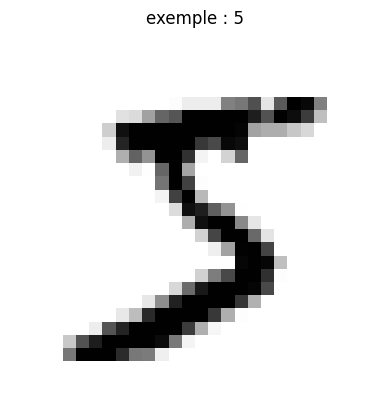

In [6]:
X, y = fetch_openml("mnist_784", version=1, return_X_y=True, as_frame=False)
X = X.astype(np.float32) / 255.0
y = y.astype(int)
print(X.shape, y.shape)

plt.imshow(X[0].reshape(28, 28), cmap="gray_r")
plt.title(f"exemple : {y[0]}")
plt.axis("off")
plt.show()

## 2. Paramètres des expériences

In [7]:
N_MAX = 200                 # un seul entraînement à 200 étapes, évalué aux étapes intermédiaires
STEPS = [10, 50, 100, 200]

# tâches
tasks = {
    "3_vs_8": ([3], [8]),
    "4_vs_9": ([4], [9]),
    "0-4_vs_5-9": ([0, 1, 2, 3, 4], [5, 6, 7, 8, 9]),
}

weak_learners = {
    "stump (prof.1)": DecisionTreeClassifier(max_depth=1, random_state=SEED),
    "arbre prof.2": DecisionTreeClassifier(max_depth=2, random_state=SEED),
    "arbre prof.3": DecisionTreeClassifier(max_depth=3, random_state=SEED),
    "arbre prof.5": DecisionTreeClassifier(max_depth=5, random_state=SEED),
    "perceptron": Perceptron(max_iter=15, tol=1e-3, random_state=SEED),
}

## 3. Expériences et matrices de confusion

Pour chaque tâche j'imprime une grille de matrices de confusion


Je stocke les métriques dans `rows` pour le tableau récapitulatif.

3_vs_8       stump (prof.1)  : 200 étapes effectivement utilisées, temps = 78.7s
3_vs_8       arbre prof.2    : 200 étapes effectivement utilisées, temps = 148.8s
3_vs_8       arbre prof.3    : 200 étapes effectivement utilisées, temps = 212.1s
3_vs_8       arbre prof.5    : 200 étapes effectivement utilisées, temps = 239.2s
3_vs_8       perceptron      : 19 étapes effectivement utilisées, temps = 3.8s


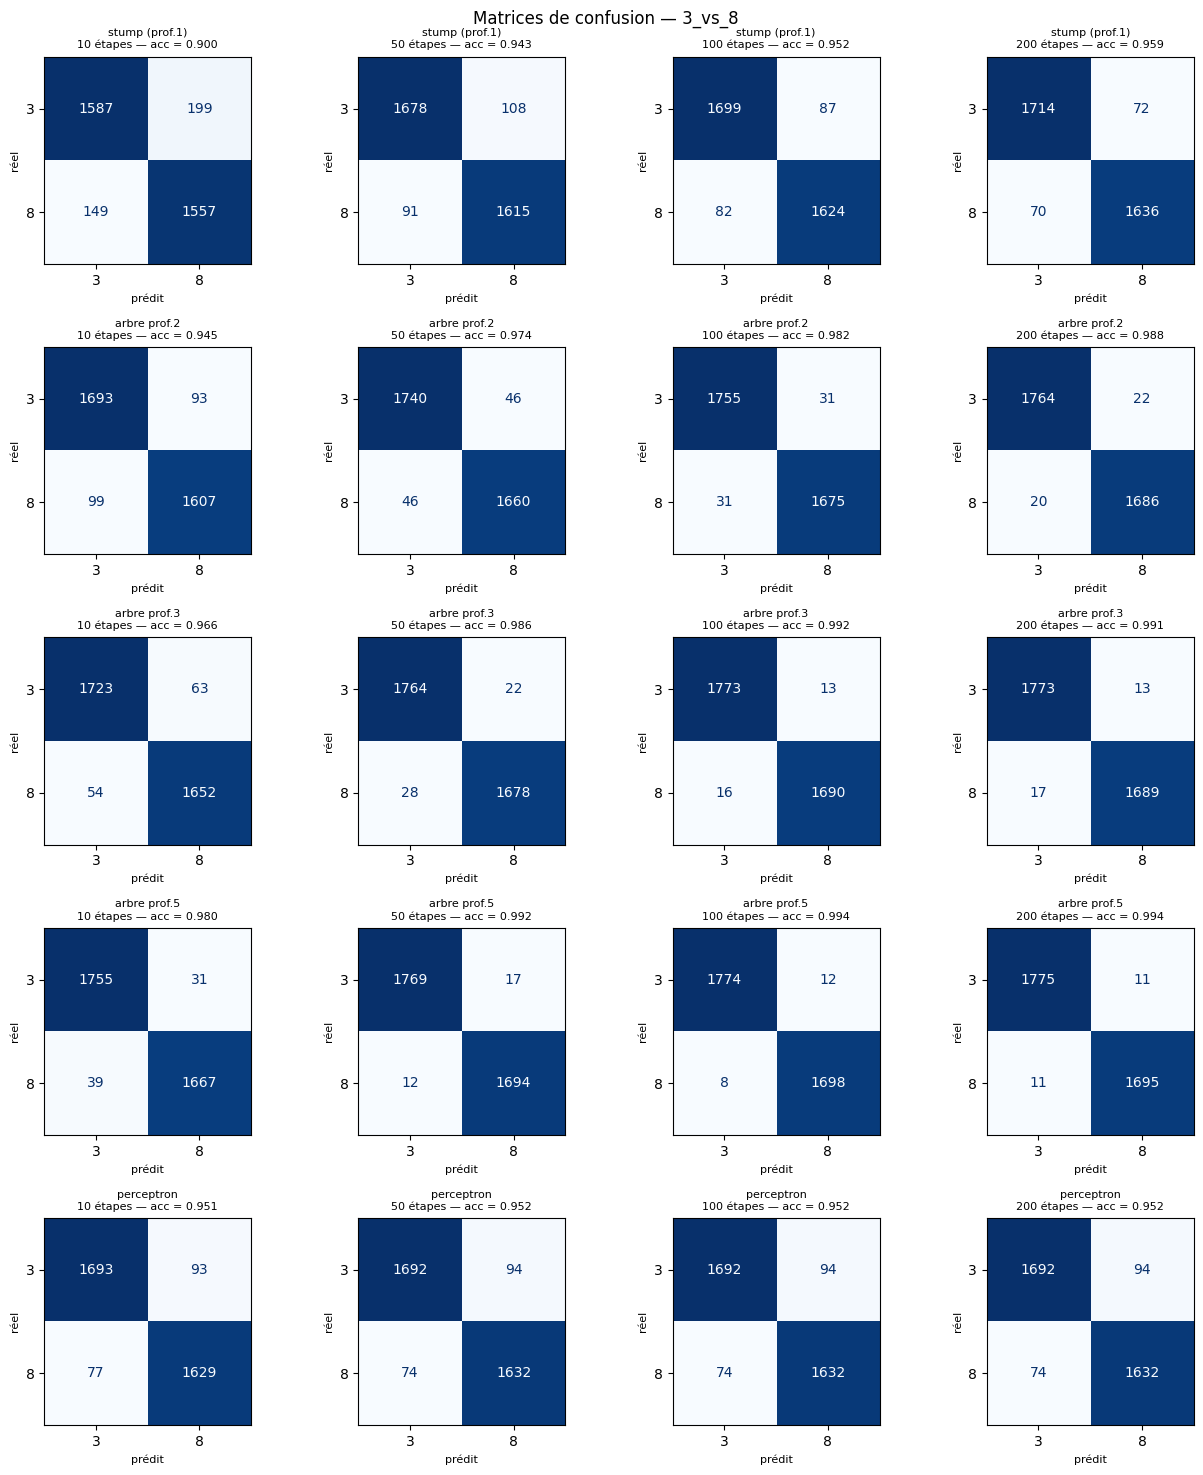

4_vs_9       stump (prof.1)  : 200 étapes effectivement utilisées, temps = 42.3s
4_vs_9       arbre prof.2    : 200 étapes effectivement utilisées, temps = 75.5s
4_vs_9       arbre prof.3    : 200 étapes effectivement utilisées, temps = 119.8s
4_vs_9       arbre prof.5    : 200 étapes effectivement utilisées, temps = 166.5s
4_vs_9       perceptron      : 19 étapes effectivement utilisées, temps = 3.7s


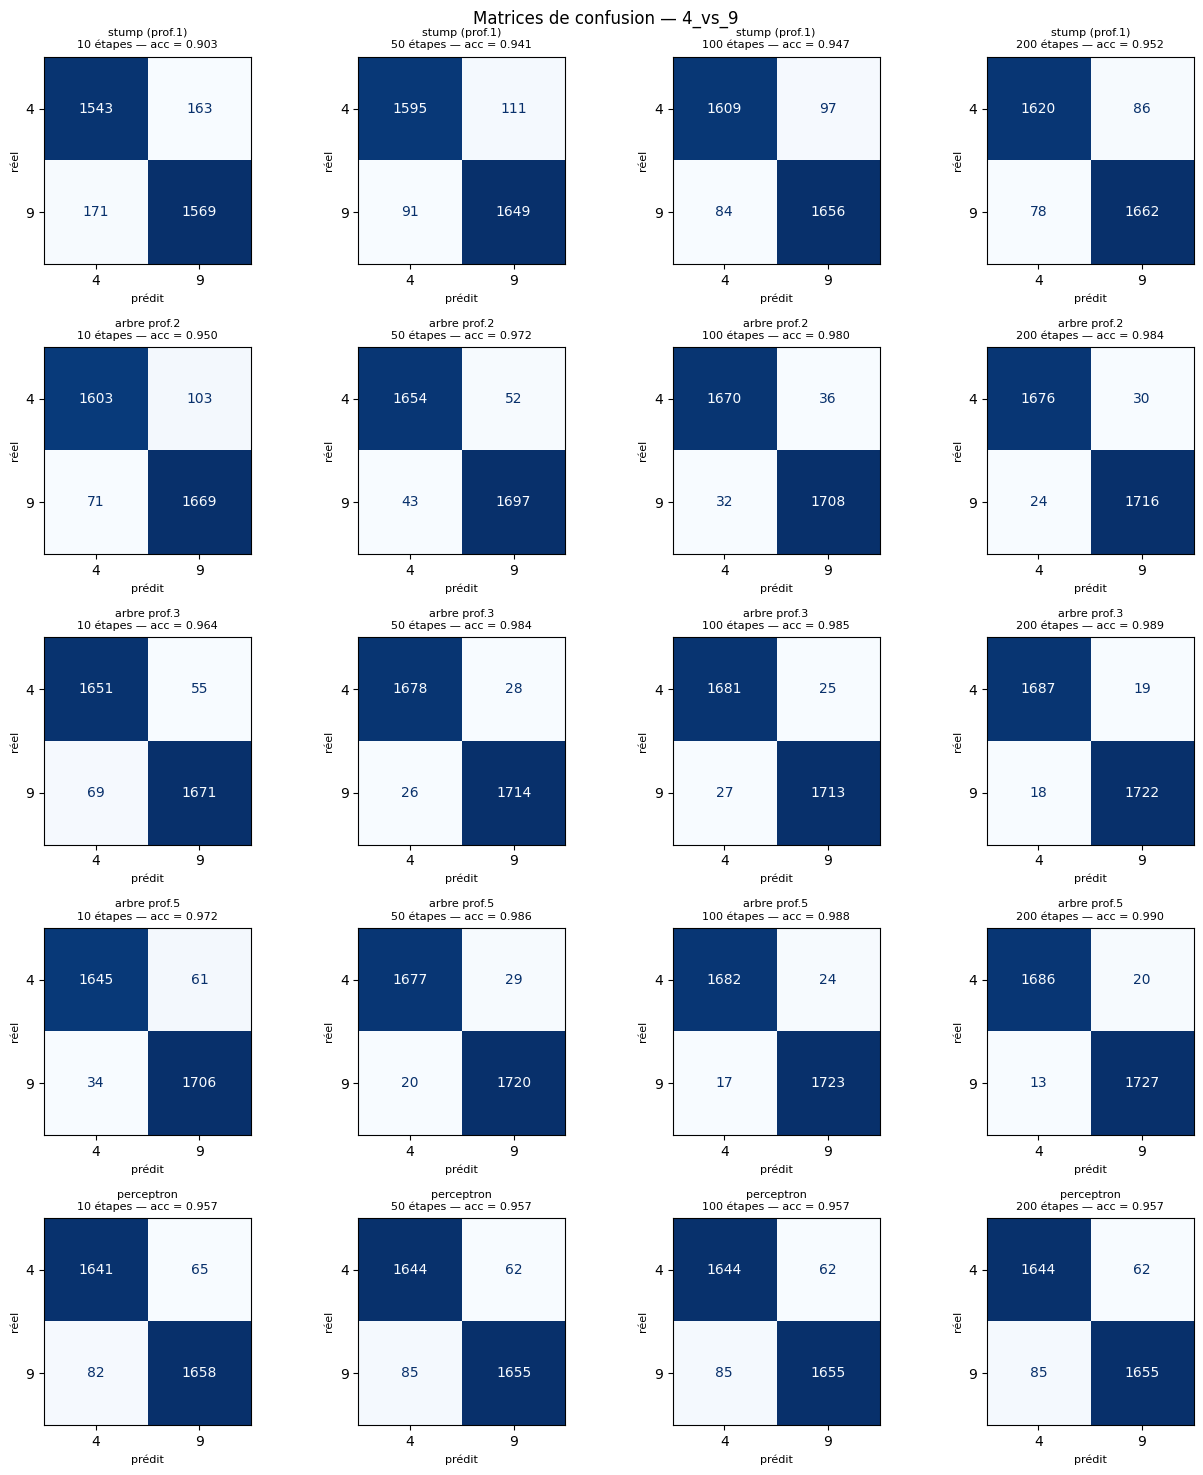

0-4_vs_5-9   stump (prof.1)  : 200 étapes effectivement utilisées, temps = 62.7s
0-4_vs_5-9   arbre prof.2    : 200 étapes effectivement utilisées, temps = 115.9s
0-4_vs_5-9   arbre prof.3    : 200 étapes effectivement utilisées, temps = 159.0s
0-4_vs_5-9   arbre prof.5    : 200 étapes effectivement utilisées, temps = 245.1s
0-4_vs_5-9   perceptron      : 16 étapes effectivement utilisées, temps = 3.0s


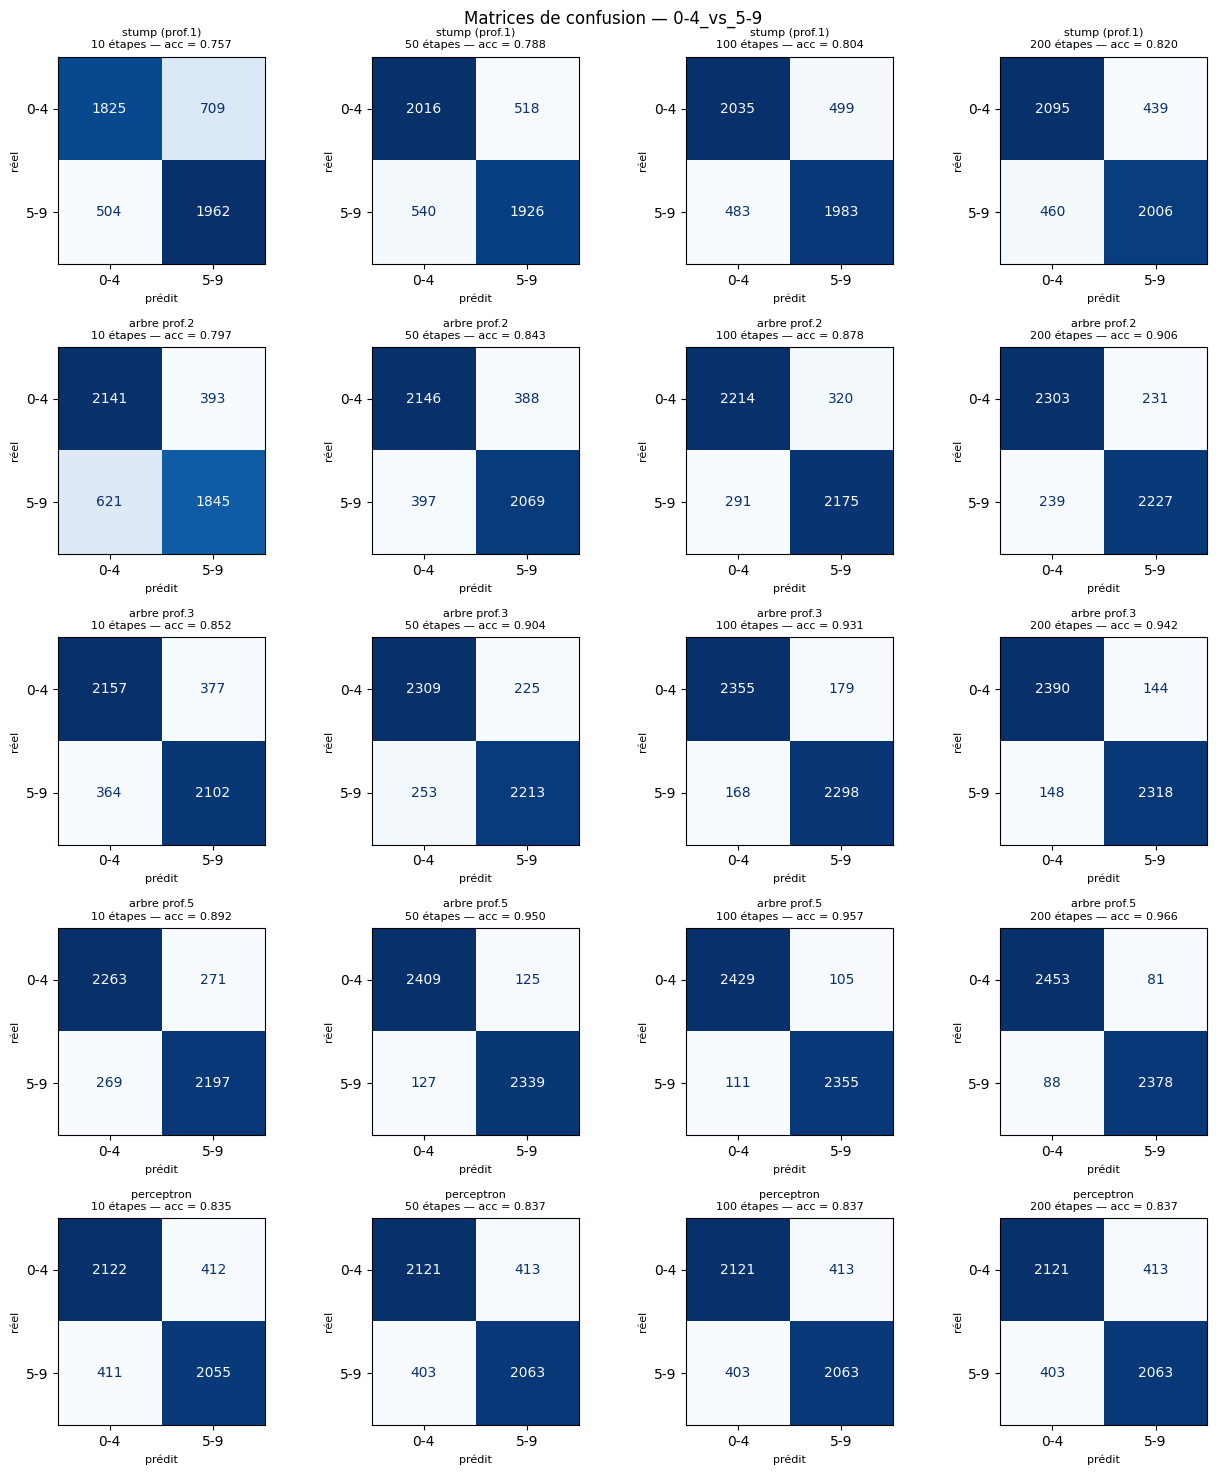

In [14]:
rows = []

for task, (c0, c1) in tasks.items():
    # données de la tâche (classe 0 / classe 1)
    mask = np.isin(y, c0 + c1)
    Xt, yt = X[mask], np.isin(y[mask], c1).astype(int)

    # Si on fait tourner sur ordinateur décommenter cette section pour éviter de perdre trop de temps à l'entraînement


    if len(yt) > 20000:   # sous-échantillonnage pour limiter le temps de calcul    # Section a commenter/décommenter selon la machine utilisée
        idx = np.random.RandomState(SEED).choice(len(yt), 20000, replace=False)     # Section a commenter/décommenter selon la machine utilisée
        Xt, yt = Xt[idx], yt[idx]                                                   # Section a commenter/décommenter selon la machine utilisée
    
    Xtr, Xte, ytr, yte = train_test_split(Xt, yt, test_size=0.25, stratify=yt, random_state=SEED)

    noms = [str(c0[0]) if len(c0) == 1 else f"{c0[0]}-{c0[-1]}",
            str(c1[0]) if len(c1) == 1 else f"{c1[0]}-{c1[-1]}"]

    fig, axes = plt.subplots(len(weak_learners), len(STEPS), squeeze=False,
                             figsize=(3.2 * len(STEPS), 3.0 * len(weak_learners)))

   

    for i, (wname, base) in enumerate(weak_learners.items()):
        t = time.time()
        ada = AdaBoostClassifier(estimator=base, n_estimators=N_MAX, random_state=SEED)
        ada.fit(Xtr, ytr)
        preds = list(ada.staged_predict(Xte))   # prédictions après n étapes
        print(f"{task:12s} {wname:15s} : {len(preds)} étapes effectivement utilisées, temps = {time.time() - t:.1f}s")

        for j, s in enumerate(STEPS):
            s_eff = min(s, len(preds))          # AdaBoost peut s'arrêter avant N_MAX et il le fait pour le perceptron
            p = preds[s_eff - 1]
            cm = confusion_matrix(yte, p, labels=[0, 1])
            prec, rapp, f1, _ = precision_recall_fscore_support(yte, p, average="binary", zero_division=0)
            acc = (p == yte).mean()
            rows.append(dict(tache=task, faible=wname, etapes=s, etapes_utilisees=s_eff,
                             accuracy=acc, precision=prec, rappel=rapp, f1=f1,
                             TN=cm[0, 0], FP=cm[0, 1], FN=cm[1, 0], TP=cm[1, 1]))

            ax = axes[i, j]
            ConfusionMatrixDisplay(cm, display_labels=noms).plot(ax=ax, colorbar=False, cmap="Blues")
            ax.set_title(f"{wname}\n{s} étapes — acc = {acc:.3f}", fontsize=8)
            ax.set_xlabel("prédit", fontsize=8)
            ax.set_ylabel("réel", fontsize=8)

    fig.suptitle(f"Matrices de confusion — {task}", fontsize=12)
    fig.tight_layout()
    plt.show()

## 5. Bilan

On peut voir que :

- Avec les perceptrons en classifieur faible  donc quis'aprennent rapidement il n'y arrive pas du tout car il s'arrête très rapidement (moins de 10 itérations) car l'erreur est plus grande que le hasard assez rapidement ce qui fait qu'adaBoost arrête le processus donc ce n'est pas un bon apprenant faible
- Pour les arbres,  plus la profondeur des apprenants faibles est grande, moins l'algorithme fait d'erreur il n'y a pas de surapprentissage mais cela demande par contre plus de temps de calcul (entre 40s et 150s pour 200 étapes)
- Le temps de calcul est démultiplié pour 0-4 vs 5-9 notamment parce qu'il y a beaucoup plus de données à traiter c'est pourquoi j'ai limité le nombre de données 
- La classe qui est de manière générale la plus facile à différencier par les algorithmes entre les trois testée est  3 vs 8 puis 4 vs 9 puis 0-4 vs 5-9 comme on peut le voir dans les matrices de confusion